# Job Dataset: salary midpoint baseline

Prepare numerical and categorical inputs and evaluate Ridge using training-only CV.

## 1. Source and reproducibility

[Job Dataset v1](https://www.kaggle.com/datasets/ravindrasinghrana/job-description-dataset) is synthetic and licensed CC0; a common currency or annual pay period is unverified. Run from `D:/AML` with the `.venv` kernel, keep the source ZIP at `data/job_dataset/raw/job-description-dataset-v1.zip`, and select **Restart Kernel and Run All**.

```powershell
.\.venv\Scripts\python.exe -m pip install numpy==2.5.4 pandas==3.0.6 scipy==1.18.1 matplotlib==3.11.2 scikit-learn==1.9.1 ipykernel==7.4.0
```

### 1.1 Imports

Import the libraries used for data preparation.

In [1]:
# AI assistance applies to the preparation code in this notebook.
from pathlib import Path
from contextlib import contextmanager
from importlib.metadata import version
import platform
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display
from sklearn.model_selection import train_test_split

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

### 1.2 Configuration

Set seed 2026, sample size 10,000 and test fraction 1/3.

In [2]:
SEED = 2026
SAMPLE_SIZE = 10_000
CHUNK_SIZE = 50_000
TEST_SIZE = 1 / 3

ROOT = Path.cwd()
ARCHIVE = ROOT / "data" / "job_dataset" / "raw" / "job-description-dataset-v1.zip"
CSV_MEMBER = "job_descriptions.csv"
SOURCE_URL = "https://www.kaggle.com/datasets/ravindrasinghrana/job-description-dataset"
assert ARCHIVE.exists(), f"Download the official v1 ZIP to {ARCHIVE}, then rerun."
print("Source:", ARCHIVE)
MODEL_SOURCE_COLUMNS = ["Experience", "Qualifications", "Salary Range", "location", "Country", "Work Type", "Company Size", "Job Title", "Role", "Company"]

Source: D:\AML\data\job_dataset\raw\job-description-dataset-v1.zip


### 1.3 Package versions

Record Python and package versions for reproduction.

In [3]:
versions = {"Python": platform.python_version()}
versions.update({name: version(name) for name in
                 ["numpy", "pandas", "matplotlib", "scikit-learn", "scipy", "ipykernel"]})
display(pd.Series(versions, name="version").to_frame())

,version
Python,3.14.4
numpy,2.5.4
pandas,3.0.6
matplotlib,3.11.2
scikit-learn,1.9.1
scipy,1.18.1
ipykernel,7.4.0


## 2. Data loading

Preview the source and document its variables.

### 2.1 Read the source preview

Read five rows directly from the ZIP, preserving source values as strings.

In [4]:
@contextmanager
def open_source_csv():
    with zipfile.ZipFile(ARCHIVE) as archive:
        with archive.open(CSV_MEMBER) as stream:
            yield stream

READ_OPTIONS = dict(dtype="string", keep_default_na=False, encoding="utf-8-sig")
with open_source_csv() as stream:
    preview = pd.read_csv(stream, nrows=5, **READ_OPTIONS)
SOURCE_COLUMNS = preview.columns.tolist()
print("Source columns:", SOURCE_COLUMNS)
display(preview[["Experience", "Qualifications", "Salary Range", "Job Title", "Role"]])

Source columns: ['Job Id', 'Experience', 'Qualifications', 'Salary Range', 'location', 'Country', 'latitude', 'longitude', 'Work Type', 'Company Size', 'Job Posting Date', 'Preference', 'Contact Person', 'Contact', 'Job Title', 'Role', 'Job Portal', 'Job Description', 'Benefits', 'skills', 'Responsibilities', 'Company', 'Company Profile']


,Experience,Qualifications,Salary Range,Job Title,Role
0,5 to 15 Years,M.Tech,$59K-$99K,Digital Marketing Specialist,Social Media Manager
1,2 to 12 Years,BCA,$56K-$116K,Web Developer,Frontend Web Developer
2,0 to 12 Years,PhD,$61K-$104K,Operations Manager,Quality Control Manager
3,4 to 11 Years,PhD,$65K-$91K,Network Engineer,Wireless Network Engineer
4,1 to 12 Years,MBA,$64K-$87K,Event Manager,Conference Manager


### 2.2 Variable definitions

Define the meaning, type and modeling role of each source column.

In [5]:
VARIABLES = {
    "Job Id": ("identifier", "trace only", "Posting identifier; excluded from inputs"),
    "Experience": ("numeric interval in text", "input", "Retain minimum and maximum required years"),
    "Qualifications": ("nominal category", "input", "Required qualification"),
    "Salary Range": ("numeric interval in text", "target source only", "Listed range midpoint in K; annual basis unverified"),
    "location": ("nominal category", "input", "Posting location label"),
    "Country": ("nominal category", "input", "Posting country label"),
    "latitude": ("continuous numeric", "optional; omitted", "Coordinates may be redundant with location/country"),
    "longitude": ("continuous numeric", "optional; omitted", "Coordinates may be redundant with location/country"),
    "Work Type": ("nominal category", "input", "Employment type"),
    "Company Size": ("numeric count", "input", "Company size as supplied"),
    "Job Posting Date": ("date", "optional; omitted", "No future-time claim under a random split"),
    "Preference": ("nominal category", "excluded initially", "Not needed for the initial stated salary task"),
    "Contact Person": ("name / identifier", "excluded", "Contact identity; no intended predictive role"),
    "Contact": ("contact / identifier", "excluded", "Contact information"),
    "Job Title": ("nominal category", "input", "Posting title"),
    "Role": ("nominal category", "input", "Posting role; can overlap with title"),
    "Job Portal": ("nominal category", "optional; omitted", "Known source label; not essential initially"),
    "Job Description": ("free/structured text", "excluded", "Free text is not used in this model"),
    "Benefits": ("free/structured text", "excluded", "Free text is not used in this model"),
    "skills": ("free/structured text", "excluded", "Free text is not used in this model"),
    "Responsibilities": ("free/structured text", "excluded", "Free text is not used in this model"),
    "Company": ("high-cardinality category", "input", "Known employer; no unseen-employer claim"),
    "Company Profile": ("free/structured text", "excluded", "Free text is not used in this model"),
}
assert set(SOURCE_COLUMNS) == set(VARIABLES)

### 2.3 Variable dictionary

Display the source variable definitions.

In [6]:
variable_dictionary = pd.DataFrame([
    {"column": col, "read_dtype": str(preview[col].dtype), "semantic_type": VARIABLES[col][0],
     "role_initial": VARIABLES[col][1], "meaning_or_unit": VARIABLES[col][2]}
    for col in SOURCE_COLUMNS
])
display(variable_dictionary)

,column,read_dtype,semantic_type,role_initial,meaning_or_unit
0,Job Id,string,identifier,trace only,Posting identifier; excluded from inputs
1,Experience,string,numeric interval in text,input,Retain minimum and maximum required years
2,Qualifications,string,nominal category,input,Required qualification
3,Salary Range,string,numeric interval in text,target source only,Listed range midpoint in K; annual basis unver...
4,location,string,nominal category,input,Posting location label
5,Country,string,nominal category,input,Posting country label
6,latitude,string,continuous numeric,optional; omitted,Coordinates may be redundant with location/cou...
7,longitude,string,continuous numeric,optional; omitted,Coordinates may be redundant with location/cou...
8,Work Type,string,nominal category,input,Employment type
9,Company Size,string,numeric count,input,Company size as supplied


## 3. Source inspection

Scan the full source in chunks to check size, missingness and target validity.

### 3.1 Missing-value rules

Treat blanks and the listed placeholder strings as missing.

In [7]:
MISSING_MARKERS = {"", "na", "n/a", "nan", "null", "none"}

def normalize_missing(frame):
    clean = frame.copy()
    for col in frame.columns:
        text = frame[col].astype("string").str.strip()
        clean[col] = text.mask(text.str.casefold().isin(MISSING_MARKERS))
    return clean

### 3.2 Salary parser

Parse `$60K-$100K` as `[60, 100]` and require finite, nonnegative, ordered endpoints. Use them only to construct the target.

In [8]:
SALARY_PATTERN = (
    r"^\s*\$\s*(?P<salary_lower_k>\d+(?:\.\d+)?)\s*[Kk]\s*[-–—]\s*"
    r"\$\s*(?P<salary_upper_k>\d+(?:\.\d+)?)\s*[Kk]\s*$"
)
TARGET_COLUMNS = ["salary_lower_k", "salary_upper_k"]

def parse_salary(series):
    endpoints = series.astype("string").str.extract(SALARY_PATTERN).astype("float64")
    finite = pd.Series(np.isfinite(endpoints.to_numpy()).all(axis=1), index=series.index)
    valid = finite & endpoints.ge(0).all(axis=1)
    valid &= endpoints["salary_lower_k"].le(endpoints["salary_upper_k"])
    return endpoints, valid

### 3.3 Full-source counts

Count all records, missing values and valid salary ranges.

In [9]:
source_n = 0
invalid_target_n = 0
source_missing = pd.Series(0, index=SOURCE_COLUMNS, dtype="int64")
eligible_parts = []
source_salary_strings = set()

with open_source_csv() as stream:
    for raw in pd.read_csv(stream, chunksize=CHUNK_SIZE, **READ_OPTIONS):
        clean = normalize_missing(raw)
        source_missing += clean.isna().sum()
        source_salary_strings.update(clean["Salary Range"].dropna().unique())
        _, valid = parse_salary(clean["Salary Range"])
        eligible_parts.append(np.flatnonzero(valid.to_numpy()) + source_n)
        invalid_target_n += int((~valid).sum())
        source_n += len(raw)

eligible_ids = np.concatenate(eligible_parts)
assert source_n == len(eligible_ids) + invalid_target_n
print(f"Original source: n={source_n:,}, columns={len(SOURCE_COLUMNS)}")
print(f"Valid target records: {len(eligible_ids):,}; invalid targets: {invalid_target_n:,}")
print("Distinct salary strings in full source:", len(source_salary_strings))

Original source: n=1,615,940, columns=23
Valid target records: 1,615,940; invalid targets: 0
Distinct salary strings in full source: 561


### 3.4 Source missingness

Report missing counts and percentages for every source column.

In [10]:
source_missing_table = source_missing.rename("missing_n_full_source").to_frame()
source_missing_table["missing_pct_full_source"] = 100 * source_missing / source_n
display(source_missing_table)

,missing_n_full_source,missing_pct_full_source
Job Id,0,0.000000
Experience,0,0.000000
Qualifications,0,0.000000
Salary Range,0,0.000000
location,0,0.000000
Country,0,0.000000
latitude,0,0.000000
longitude,0,0.000000
Work Type,0,0.000000
Company Size,0,0.000000


## 4. Random sampling

Select 10,000 eligible records without replacement using seeded random priorities.

### 4.1 Select record IDs

Choose the sample using the fixed seed and target-validity rule.

In [11]:
assert 1 < SAMPLE_SIZE <= len(eligible_ids)
sampling_rng = np.random.default_rng(SEED)
priorities = sampling_rng.random(len(eligible_ids))
selected_positions = np.argpartition(priorities, SAMPLE_SIZE - 1)[:SAMPLE_SIZE]
sample_ids = np.sort(eligible_ids[selected_positions])
assert len(np.unique(sample_ids)) == SAMPLE_SIZE
print("Selected records:", len(sample_ids))

Selected records: 10000


### 4.2 Load the sample

Read only the selected numerical/categorical source fields and the salary target for the sampled records.

In [12]:
sample_parts = []
offset = 0
with open_source_csv() as stream:
    for raw in pd.read_csv(stream, chunksize=CHUNK_SIZE, usecols=MODEL_SOURCE_COLUMNS, **READ_OPTIONS):
        chosen = sample_ids[(sample_ids >= offset) & (sample_ids < offset + len(raw))]
        part = raw.iloc[chosen - offset].copy()
        part.index = chosen
        sample_parts.append(part)
        offset += len(raw)

sample_source = pd.concat(sample_parts).sort_index()
sample_source.index.name = "source_record_index"
sample_clean = normalize_missing(sample_source)
assert len(sample_source) == SAMPLE_SIZE and sample_source.index.is_unique
display(sample_clean[["Experience", "Qualifications", "Salary Range", "Job Title"]].head())

,Experience,Qualifications,Salary Range,Job Title
source_record_index,,,,
58,2 to 10 Years,B.Com,$65K-$88K,Investment Banker
420,3 to 10 Years,MCA,$64K-$98K,Software Engineer
468,3 to 12 Years,B.Com,$59K-$83K,Veterinarian
733,0 to 12 Years,BBA,$60K-$102K,Software Engineer
814,0 to 10 Years,BA,$56K-$89K,UX Researcher


### 4.3 Sample checks

Inspect the retained sampled columns and check duplicate retained records.

In [13]:
sample_clean.info()
print("Duplicate retained sampled records:", int(sample_clean.duplicated().sum()))
print("Distinct salary strings in sample:", sample_clean["Salary Range"].nunique())

<class 'pandas.DataFrame'>
Index: 10000 entries, 58 to 1615898
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Experience      10000 non-null  string
 1   Qualifications  10000 non-null  string
 2   Salary Range    10000 non-null  string
 3   location        10000 non-null  string
 4   Country         10000 non-null  string
 5   Work Type       10000 non-null  string
 6   Company Size    10000 non-null  string
 7   Job Title       10000 non-null  string
 8   Role            10000 non-null  string
 9   Company         10000 non-null  string
dtypes: string(10)
memory usage: 859.4 KB
Duplicate retained sampled records: 0
Distinct salary strings in sample: 561


## 5. Inputs and target

Use three numerical and seven categorical inputs to predict the salary midpoint.

### 5.1 Target

Compute `y = (salary_lower_k + salary_upper_k) / 2` in listed K units.

In [14]:
salary_endpoints, valid_sample_target = parse_salary(sample_clean["Salary Range"])
assert valid_sample_target.all()
y = salary_endpoints.mean(axis=1).rename("salary_midpoint_k")
y.index.name = "source_record_index"
assert y.shape == (len(sample_clean),)
assert np.isfinite(y.to_numpy()).all() and y.ge(0).all()
display(y.head().to_frame())
print("Target shape:", y.shape)

,salary_midpoint_k
source_record_index,
58,76.5
420,81.0
468,71.0
733,81.0
814,72.5


Target shape: (10000,)


### 5.2 Selected inputs

Use experience endpoints, company size, qualification, location, country, work type, title, role and company.

In [15]:
NUMERIC_INPUTS = ["experience_min_years", "experience_max_years", "Company Size"]
CATEGORICAL_INPUTS = ["Qualifications", "location", "Country", "Work Type", "Job Title", "Role", "Company"]
FEATURE_COLUMNS = NUMERIC_INPUTS + CATEGORICAL_INPUTS
print("Numerical inputs:", NUMERIC_INPUTS)
print("Categorical inputs:", CATEGORICAL_INPUTS)

Numerical inputs: ['experience_min_years', 'experience_max_years', 'Company Size']
Categorical inputs: ['Qualifications', 'location', 'Country', 'Work Type', 'Job Title', 'Role', 'Company']


### 5.3 Experience

Parse and validate the numerical experience endpoints.

In [16]:
def parse_experience(series):
    result = series.astype("string").str.extract(
        r"(?i)^\s*(\d+(?:\.\d+)?)\s+to\s+(\d+(?:\.\d+)?)\s+years?\s*$"
    ).astype("float64")
    result.columns = ["experience_min_years", "experience_max_years"]
    finite = pd.Series(np.isfinite(result.to_numpy()).all(axis=1), index=series.index)
    valid = finite & result.ge(0).all(axis=1)
    valid &= result.iloc[:, 0].le(result.iloc[:, 1])
    return result.where(valid, np.nan)

In [17]:
experience = parse_experience(sample_clean["Experience"])
X = experience.copy()
display(X.head())

,experience_min_years,experience_max_years
source_record_index,,
58,2.0,10.0
420,3.0,10.0
468,3.0,12.0
733,0.0,12.0
814,0.0,10.0


### 5.4 Company size

Parse company size as a positive integer count.

In [18]:
company_size = pd.to_numeric(sample_clean["Company Size"], errors="coerce").astype("float64")
valid_size = np.isfinite(company_size) & company_size.ge(1) & company_size.mod(1).eq(0)
invalid_company_size_n = int((sample_clean["Company Size"].notna() & ~valid_size).sum())
X["Company Size"] = company_size.where(valid_size)
print("Invalid company size values in sample:", invalid_company_size_n)

Invalid company size values in sample: 0


### 5.5 Categorical inputs

Retain the selected nominal labels for one-hot encoding.

In [19]:
for column in CATEGORICAL_INPUTS:
    X[column] = sample_clean[column].astype("string")
X = X[FEATURE_COLUMNS]
X.index.name = "source_record_index"
display(X.head())

,experience_min_years,experience_max_years,Company Size,Qualifications,location,Country,Work Type,Job Title,Role,Company
source_record_index,,,,,,,,,,
58,2.0,10.0,45782.0,B.Com,Castries,St. Lucia,Part-Time,Investment Banker,Financial Analyst,General Electric
420,3.0,10.0,68322.0,MCA,San Jose,Costa Rica,Part-Time,Software Engineer,DevOps Engineer,China Mobile
468,3.0,12.0,28841.0,B.Com,Saint John's,Antigua and Barbuda,Full-Time,Veterinarian,Small Animal Veterinarian,BlackRock
733,0.0,12.0,116882.0,BBA,Dushanbe,Tajikistan,Part-Time,Software Engineer,Backend Developer,Kainos Group
814,0.0,10.0,130256.0,BA,Zagreb,Croatia,Temporary,UX Researcher,Usability Analyst,SSE plc


### 5.6 Input checks

Verify X/y alignment, exclude salary-derived inputs and check repeated input tuples.

In [20]:
assert X.index.equals(y.index) and X.index.is_unique
assert set(X.columns).isdisjoint({"Salary Range", *TARGET_COLUMNS, "salary_midpoint_k", "salary_width_k", "Job Id"})
assert not X.isna().any().any(), "Selected inputs contain missing/invalid values; inspect them before fitting."
assert np.isfinite(X[NUMERIC_INPUTS].to_numpy()).all()
duplicate_input_n = int(X.duplicated().sum())
print("Repeated complete input tuples:", duplicate_input_n)
assert duplicate_input_n == 0, "Review repeated-input overlap before using a random row split."
print(f"Analytical sample: n={len(X):,}; numerical inputs={len(NUMERIC_INPUTS)}, categorical inputs={len(CATEGORICAL_INPUTS)}")
display(X.dtypes.astype(str).rename("dtype").to_frame())

Repeated complete input tuples: 0
Analytical sample: n=10,000; numerical inputs=3, categorical inputs=7


,dtype
experience_min_years,float64
experience_max_years,float64
Company Size,float64
Qualifications,string
location,string
Country,string
Work Type,string
Job Title,string
Role,string
Company,string


## 6. Training/test split

Split the fixed sample into 6,666 training and 3,334 test records using seed 2026.

### 6.1 Create the split

Create the split and sort record IDs for consistent row order.

In [21]:
train_ids, test_ids = train_test_split(X.index.to_numpy(), test_size=TEST_SIZE, random_state=SEED)
train_ids, test_ids = np.sort(train_ids), np.sort(test_ids)
X_train, X_test = X.loc[train_ids].copy(), X.loc[test_ids].copy()
y_train, y_test = y.loc[train_ids].copy(), y.loc[test_ids].copy()

### 6.2 Split checks

Check alignment, disjoint membership and complete sample coverage.

In [22]:
assert set(train_ids).isdisjoint(test_ids)
assert set(train_ids) | set(test_ids) == set(X.index)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert X_train.columns.equals(X_test.columns)
display(pd.DataFrame({"n": [len(X_train), len(X_test)],
                      "fraction": [len(X_train) / len(X), len(X_test) / len(X)]},
                     index=["training/development", "final test"]))

,n,fraction
training/development,6666,0.6666
final test,3334,0.3334


## 7. Training EDA

Summarize training inputs and the midpoint target.

### 7.1 Numeric inputs

Inspect training numeric summaries and missing counts.

In [23]:
display(X_train[NUMERIC_INPUTS].describe().T)
display(X_train.isna().sum().rename("missing_n_training").to_frame())

,count,mean,std,min,25%,50%,75%,max
experience_min_years,6666.0,2.510201,1.698585,0.0,1.00,3.0,4.00,5.0
experience_max_years,6666.0,11.508701,2.282324,8.0,10.00,12.0,13.00,15.0
Company Size,6666.0,73825.526853,35565.294989,12675.0,42769.25,74314.5,104350.75,134833.0


,missing_n_training
experience_min_years,0
experience_max_years,0
Company Size,0
Qualifications,0
location,0
Country,0
Work Type,0
Job Title,0
Role,0
Company,0


### 7.2 Target summary

Summarize training salary midpoints in K units.

In [24]:
display(y_train.describe().to_frame())

,salary_midpoint_k
count,6666.000000
mean,82.550180
std,7.658204
min,67.500000
25%,76.000000
50%,82.500000
75%,89.000000
max,97.500000


### 7.3 Category frequencies

Count qualifications and work types in the training set.

In [25]:
for column in ["Qualifications", "Work Type"]:
    display(X_train[column].value_counts(dropna=False).rename("n_training").to_frame())

,n_training
Qualifications,
M.Tech,699
PhD,695
BA,677
BCA,671
B.Com,668
MBA,667
MCA,653
M.Com,650
BBA,643


,n_training
Work Type,
Part-Time,1379
Intern,1377
Contract,1306
Full-Time,1303
Temporary,1301


### 7.4 Target distribution

Plot the training salary-midpoint distribution.

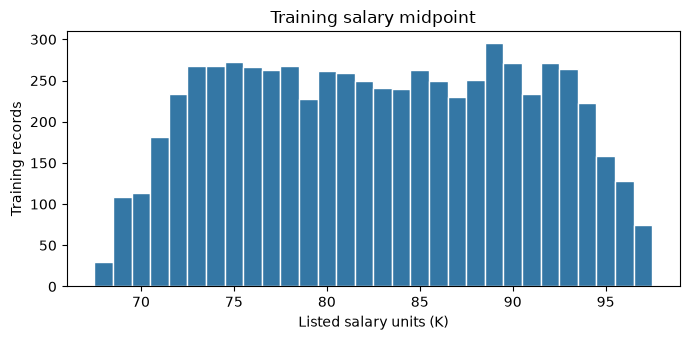

In [26]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(y_train, bins=30, color="#3477A5", edgecolor="white")
ax.set(title="Training salary midpoint", xlabel="Listed salary units (K)", ylabel="Training records")
fig.tight_layout()
plt.show()

## 8. Reproducibility

Keep split assignments, seed and package versions in this notebook.

### 8.1 Split assignments

Keep source-record IDs and training/test membership in memory.

In [27]:
split_indices = pd.DataFrame(index=X.index)
split_indices.index.name = "source_record_index"
split_indices["split"] = "training"
split_indices.loc[test_ids, "split"] = "final_test"
display(split_indices["split"].value_counts().rename("records").to_frame())

,records
split,
training,6666
final_test,3334


### 8.2 Run information

Display the source version, seed, sample size, split fraction and package versions.

In [28]:
reproduction_lines = [f"source={SOURCE_URL}", "source_version=1", f"seed={SEED}",
                      f"sample_size={SAMPLE_SIZE}", f"test_size={TEST_SIZE}"]
reproduction_lines += [f"{name}={value}" for name, value in versions.items()]
print("\n".join(reproduction_lines))

source=https://www.kaggle.com/datasets/ravindrasinghrana/job-description-dataset
source_version=1
seed=2026
sample_size=10000
test_size=0.3333333333333333
Python=3.14.4
numpy=2.5.4
pandas=3.0.6
matplotlib=3.11.2
scikit-learn=1.9.1
scipy=1.18.1
ipykernel=7.4.0


## 9. Ridge baseline

Scale numerical inputs and one-hot encode categories inside each training fold. Five shuffled folds select alpha from `10**[-2, -1, 0, 1, 2, 3, 4, 5, 6]` by mean validation MSE.

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

ALPHAS = np.logspace(-2, 6, 9)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train))
assert all(set(train_ids[a]).isdisjoint(test_ids) and
           set(train_ids[b]).isdisjoint(test_ids) for a, b in cv_splits)
print("Fixed alpha grid:", ALPHAS)
print("Training/validation fold sizes:", [(len(a), len(b)) for a, b in cv_splits])

Fixed alpha grid: [1.e-02 1.e-01 1.e+00 1.e+01 1.e+02 1.e+03 1.e+04 1.e+05 1.e+06]
Training/validation fold sizes: [(5332, 1334), (5333, 1333), (5333, 1333), (5333, 1333), (5333, 1333)]


### 9.1 Pipeline

Build the preprocessing and Ridge pipeline.

In [30]:
preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC_INPUTS),
    ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=True), CATEGORICAL_INPUTS),
], sparse_threshold=1.0)
ridge_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("ridge", Ridge(solver="lsqr", tol=1e-8, max_iter=10_000)),
])

### 9.2 Select alpha

Tune alpha on training folds and refit the selected pipeline on all training records.

In [31]:
search = GridSearchCV(
    ridge_pipeline, {"ridge__alpha": ALPHAS},
    scoring="neg_mean_squared_error", cv=cv_splits,
    refit=True, n_jobs=1, error_score="raise",
)
search.fit(X_train, y_train)
selected_model = search.best_estimator_
selected_alpha = float(search.best_params_["ridge__alpha"])
cv_table = pd.DataFrame({
    "alpha": [float(v) for v in search.cv_results_["param_ridge__alpha"]],
    "mean_validation_mse_k2": -search.cv_results_["mean_test_score"],
    "sd_validation_mse_k2": search.cv_results_["std_test_score"],
})
for fold in range(5):
    cv_table[f"fold_{fold + 1}_mse_k2"] = -search.cv_results_[f"split{fold}_test_score"]
display(cv_table.round(6))
print("Selected alpha:", selected_alpha)
print("At grid boundary:", selected_alpha in [ALPHAS[0], ALPHAS[-1]])

,alpha,mean_validation_mse_k2,sd_validation_mse_k2,fold_1_mse_k2,fold_2_mse_k2,fold_3_mse_k2,fold_4_mse_k2,fold_5_mse_k2
0,0.01,82.323033,2.040884,81.097008,79.481433,83.302368,82.205801,85.528554
1,0.10,81.331590,2.017204,80.153007,78.477116,82.409846,81.184118,84.433861
2,1.00,75.130859,1.683298,74.271775,72.462445,76.432334,75.210045,77.277693
3,10.00,63.860867,0.882899,63.177199,62.624646,64.657355,64.986706,63.858429
4,100.00,59.277125,1.095551,57.584304,59.070494,59.708479,60.967494,59.054856
5,1000.00,58.676477,1.294097,56.565134,58.414798,59.145574,60.580981,58.675898
6,10000.00,58.644172,1.331890,56.516254,58.314500,59.148211,60.638470,58.603424
7,100000.00,58.650179,1.338892,56.526295,58.310510,59.171146,60.665186,58.577760
8,1000000.00,58.651819,1.339714,56.528605,58.311093,59.175160,60.669304,58.574934


Selected alpha: 10000.0
At grid boundary: False


### 9.3 Mean reference

Evaluate a training-mean predictor on the same folds. The selected CV score is a tuning score; fold SD is not a confidence interval.

In [32]:
dummy_inputs = np.zeros((len(y_train), 1))
dummy_cv_mse = -cross_val_score(
    DummyRegressor(strategy="mean"), dummy_inputs, y_train,
    scoring="neg_mean_squared_error", cv=cv_splits, n_jobs=1,
)
dummy_model = DummyRegressor(strategy="mean").fit(dummy_inputs, y_train)
ridge_cv_mse = cv_table.loc[search.best_index_, [f"fold_{i + 1}_mse_k2" for i in range(5)]].to_numpy(float)
cv_comparison = pd.DataFrame({
    "mean_validation_mse_k2": [ridge_cv_mse.mean(), dummy_cv_mse.mean()],
    "sd_validation_mse_k2": [ridge_cv_mse.std(), dummy_cv_mse.std()],
}, index=["Ridge", "Training mean"])
encoded_d = len(selected_model.named_steps["preprocess"].get_feature_names_out())
display(cv_comparison.round(6))
print("Encoded input dimension fitted on all training records:", encoded_d)
print("No test predictions have been made yet.")

,mean_validation_mse_k2,sd_validation_mse_k2
Ridge,58.644172,1.331890
Training mean,58.652023,1.339807


Encoded input dimension fitted on all training records: 1858
No test predictions have been made yet.


## 10. Test evaluation

Report midpoint MSE, RMSE, MAE and R² for the fixed Ridge and mean-reference models. This test set was inspected in earlier experiments; the current structured-only inputs follow the requested simplification and all tuning uses training CV.

In [33]:
def evaluate_midpoint(model_name, truth, prediction):
    prediction = np.asarray(prediction)
    assert prediction.shape == truth.shape and np.isfinite(prediction).all()
    mse = mean_squared_error(truth, prediction)
    return {
        "model": model_name,
        "test_mse_k2": float(mse),
        "test_rmse_k": float(np.sqrt(mse)),
        "test_mae_k": float(mean_absolute_error(truth, prediction)),
        "test_r2": float(r2_score(truth, prediction)),
    }

In [34]:
test_predictions = {
    "Ridge": selected_model.predict(X_test),
    "Training mean": dummy_model.predict(np.zeros((len(X_test), 1))),
}
results = pd.DataFrame([
    evaluate_midpoint(name, y_test, pred) for name, pred in test_predictions.items()
]).set_index("model")
results["cv_mean_mse_k2"] = cv_comparison["mean_validation_mse_k2"]
results["cv_sd_mse_k2"] = cv_comparison["sd_validation_mse_k2"]
results["alpha"] = [selected_alpha, np.nan]
results["n_train"], results["n_test"] = len(X_train), len(X_test)
display(results.round(6))

,test_mse_k2,test_rmse_k,test_mae_k,test_r2,cv_mean_mse_k2,cv_sd_mse_k2,alpha,n_train,n_test
model,,,,,,,,,
Ridge,56.894251,7.542828,6.469571,0.000399,58.644172,1.331890,10000.0,6666,3334
Training mean,56.917566,7.544373,6.469471,-0.000011,58.652023,1.339807,NaN,6666,3334
